Saving RS_NP_DATA.xlsx to RS_NP_DATA.xlsx
Uploaded: ['RS_NP_DATA.xlsx']
Device: cuda
Parsed 78336 / 78336 SMILES. Dropping 0 invalid.
Labels -> pathway: 7, superclass: 70, class: 652
Atom feature dim: 23 | Bond feature dim: 6
Built 78336 graphs in 101.6s
Split -> train 46746, val 15655, test 15935

=== Run seed=42 | trainable params: 4,987,609 ===
epoch 001 | loss 5.1821 | val F1 path 0.8382 super 0.4993 class 0.2404 | mean 0.5260 | 9.3s
epoch 002 | loss 3.4005 | val F1 path 0.8727 super 0.6476 class 0.4075 | mean 0.6426 | 8.3s
epoch 003 | loss 2.8622 | val F1 path 0.9046 super 0.7281 class 0.5175 | mean 0.7167 | 8.2s
epoch 004 | loss 2.5724 | val F1 path 0.9308 super 0.7837 class 0.6022 | mean 0.7722 | 8.1s
epoch 005 | loss 2.3961 | val F1 path 0.9318 super 0.7925 class 0.6357 | mean 0.7867 | 8.2s
epoch 006 | loss 2.2631 | val F1 path 0.9403 super 0.8139 class 0.6660 | mean 0.8067 | 8.2s
epoch 007 | loss 2.1684 | val F1 path 0.9456 super 0.8260 class 0.6916 | mean 0.8211 | 8.2s
epoch 

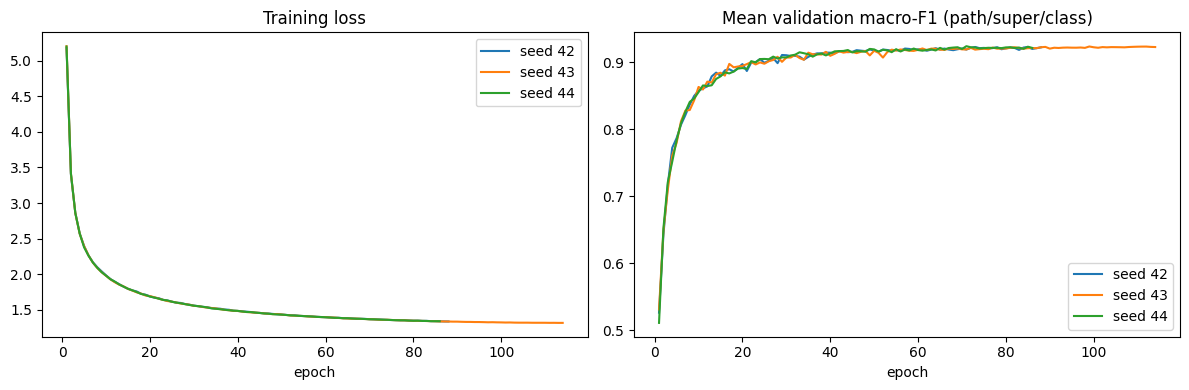


All outputs saved to: /content/ginestra_outputs


In [1]:
# %% [markdown]
# # GINESTRA-style GNN for natural product classification (improved end-to-end pipeline)
# Runtime: **GPU** (Runtime > Change runtime type > T4 GPU).
# Input: `RS_NP_DATA.xlsx` (columns: index=SMILES, Pathway, Super_class, Class).
# Model: GINE (edge-aware GIN) encoder + one shared trunk with three heads
# (pathway / superclass / class) trained jointly, with hierarchy-aware prediction.

# %% Cell 1 - install dependencies (Colab)
!pip -q install rdkit torch_geometric openpyxl

# %% Cell 2 - upload the dataset (run once; pick RS_NP_DATA.xlsx)
from google.colab import files
uploaded = files.upload()
print("Uploaded:", list(uploaded.keys()))

# %% Cell 3 - imports, config and reproducibility helpers
import os, copy, random, time, json
import numpy as np
import pandas as pd
from rdkit import Chem, RDLogger
from sklearn.metrics import f1_score, accuracy_score
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GINEConv, global_add_pool

RDLogger.DisableLog("rdApp.*")

CFG = dict(
    data_path="/content/RS_NP_DATA.xlsx",
    out_dir="/content/ginestra_outputs",
    subsample=None,          # set e.g. 5000 for a quick debug run
    split_seed=42,           # the split is fixed so every run is compared on the same test set
    seed=42,                 # base seed for model initialisation; runs use seed, seed+1, ...
    n_runs=3,
    epochs=120,
    patience=15,
    batch_size=128,
    hidden=512,
    n_layers=4,
    head_dim=1024,
    dropout=0.3,
    lr=5e-4,
    weight_decay=1e-5,
    label_smoothing=0.05,
    level_weights={"path": 1.0, "super": 1.0, "class": 1.0},
    train_frac=0.6,
    val_frac=0.2,           # test = remainder (20%)
)
os.makedirs(CFG["out_dir"], exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
LEVELS = ["path", "super", "class"]
print("Device:", DEVICE)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

# %% Cell 4 - load and clean the dataset
df = pd.read_excel(CFG["data_path"])
df = df.rename(columns={"index": "SMILES", "Super_class": "Superclass"})
df = (df.dropna(subset=["SMILES", "Pathway", "Superclass", "Class"])
        .drop_duplicates(subset="SMILES")
        .reset_index(drop=True))

valid = np.array([Chem.MolFromSmiles(s) is not None for s in df["SMILES"]])  # parse once to validate
print(f"Parsed {valid.sum()} / {len(df)} SMILES. Dropping {(~valid).sum()} invalid.")
df = df[valid].reset_index(drop=True)

if CFG["subsample"]:
    df = df.sample(n=CFG["subsample"], random_state=0).reset_index(drop=True)
    print(f"Debug subsample: {len(df)} molecules")

# Label vocabularies and integer targets
path_vocab = sorted(df["Pathway"].unique())
super_vocab = sorted(df["Superclass"].unique())
class_vocab = sorted(df["Class"].unique())
N_PATH, N_SUPER, N_CLASS = len(path_vocab), len(super_vocab), len(class_vocab)
df["y_path"] = df["Pathway"].map({v: i for i, v in enumerate(path_vocab)})
df["y_super"] = df["Superclass"].map({v: i for i, v in enumerate(super_vocab)})
df["y_class"] = df["Class"].map({v: i for i, v in enumerate(class_vocab)})
print(f"Labels -> pathway: {N_PATH}, superclass: {N_SUPER}, class: {N_CLASS}")

# Hierarchy maps (class -> superclass, class -> pathway). Each class has one parent per level.
pairs = df[["y_class", "y_super", "y_path"]].drop_duplicates()
assert pairs["y_class"].is_unique, "A class maps to more than one superclass/pathway"
class_to_super = np.zeros(N_CLASS, dtype=np.int64)
class_to_path = np.zeros(N_CLASS, dtype=np.int64)
class_to_super[pairs["y_class"].values] = pairs["y_super"].values
class_to_path[pairs["y_class"].values] = pairs["y_path"].values

# %% Cell 5 - molecular featurisation (same chemistry as the original repo, plus an 'Other' atom bucket)
ATOM_SYMBOLS = ['S', 'Sn', 'In', 'Br', 'F', 'Cl', 'B', 'N', 'O', 'I', 'C', 'Co', 'P', 'Other']
DEG_CHOICES = [0, 1, 2, 3, 4, "MoreThanFour"]
HYB_CHOICES = ["S", "SP", "SP2", "SP3", "SP3D", "SP3D2", "OTHER"]
BOND_CHOICES = [Chem.BondType.SINGLE, Chem.BondType.DOUBLE, Chem.BondType.TRIPLE, Chem.BondType.AROMATIC]

def one_hot(value, choices):
    vec = [0] * len(choices)
    # unknown values fall into the last bucket (same convention as the original repo)
    vec[choices.index(value) if value in choices else len(choices) - 1] = 1
    return vec

def atom_features(atom):
    sym = atom.GetSymbol()
    if sym not in ATOM_SYMBOLS[:-1]:
        sym = "Other"                                   # FIX: unknown elements no longer collapse into 'P'
    feats = [(ATOM_SYMBOLS.index(sym) + 1) / len(ATOM_SYMBOLS)]
    deg = atom.GetDegree()
    feats += one_hot(deg if deg <= 4 else "MoreThanFour", DEG_CHOICES)
    nh = atom.GetTotalNumHs()
    feats += one_hot(nh if nh <= 4 else "MoreThanFour", DEG_CHOICES)
    feats += [atom.GetFormalCharge()]
    feats += one_hot(str(atom.GetHybridization()), HYB_CHOICES)
    feats += [int(atom.IsInRing()), int(atom.GetIsAromatic())]
    return feats

def bond_features(bond):
    return one_hot(bond.GetBondType(), BOND_CHOICES) + [int(bond.GetIsConjugated()), int(bond.IsInRing())]

ATOM_DIM = len(atom_features(Chem.MolFromSmiles(df["SMILES"].iloc[0]).GetAtomWithIdx(0)))
BOND_DIM = len(BOND_CHOICES) + 2   # 4 bond-type one-hot + conjugated + in-ring
print(f"Atom feature dim: {ATOM_DIM} | Bond feature dim: {BOND_DIM}")

def mol_to_data(mol, y_path, y_super, y_class):
    x = torch.tensor([atom_features(a) for a in mol.GetAtoms()], dtype=torch.float)
    src, dst, eattr = [], [], []
    for b in mol.GetBonds():
        i, j = b.GetBeginAtomIdx(), b.GetEndAtomIdx()
        f = bond_features(b)
        src += [i, j]; dst += [j, i]; eattr += [f, f]     # undirected bond -> two directed edges
    edge_index = torch.tensor([src, dst], dtype=torch.long).view(2, -1)
    edge_attr = torch.tensor(eattr, dtype=torch.float).view(-1, BOND_DIM)
    return Data(x=x, edge_index=edge_index, edge_attr=edge_attr,
                y_path=torch.tensor([y_path]), y_super=torch.tensor([y_super]),
                y_class=torch.tensor([y_class]))

t0 = time.time()
targets = df[["y_path", "y_super", "y_class"]].values
data_list = [mol_to_data(Chem.MolFromSmiles(s), *t) for s, t in zip(df["SMILES"], targets)]
print(f"Built {len(data_list)} graphs in {time.time() - t0:.1f}s")

# %% Cell 6 - stratified split (per class, 60/20/20) - same idea as the paper, fixed seed
def stratified_class_split(y, frac_train, frac_val, seed):
    rng = np.random.default_rng(seed)
    tr, va, te = [], [], []
    for c in np.unique(y):
        idx = np.where(y == c)[0]
        rng.shuffle(idx)
        n = len(idx)
        a, b = int(frac_train * n), int((frac_train + frac_val) * n)
        tr += idx[:a].tolist(); va += idx[a:b].tolist(); te += idx[b:].tolist()
    return np.array(tr), np.array(va), np.array(te)

tr_idx, va_idx, te_idx = stratified_class_split(df["y_class"].values,
                                                CFG["train_frac"], CFG["val_frac"], CFG["split_seed"])
print(f"Split -> train {len(tr_idx)}, val {len(va_idx)}, test {len(te_idx)}")

train_loader = DataLoader([data_list[i] for i in tr_idx], batch_size=CFG["batch_size"],
                          shuffle=True, drop_last=True)     # drop_last avoids a 1-sample BatchNorm batch
val_loader = DataLoader([data_list[i] for i in va_idx], batch_size=CFG["batch_size"], shuffle=False)
test_loader = DataLoader([data_list[i] for i in te_idx], batch_size=CFG["batch_size"], shuffle=False)
# FIX: the original code used drop_last=True on val/test, silently discarding up to 31 molecules.

# %% Cell 7 - model: GINE encoder with shared trunk and three hierarchical heads
class GINEMultiHead(nn.Module):
    def __init__(self, atom_dim, bond_dim, n_path, n_super, n_class,
                 hidden, n_layers, head_dim, dropout):
        super().__init__()
        self.inp = nn.Linear(atom_dim, hidden)
        self.convs = nn.ModuleList()
        self.norms = nn.ModuleList()
        for _ in range(n_layers):
            mlp = nn.Sequential(nn.Linear(hidden, hidden), nn.BatchNorm1d(hidden),
                                nn.ReLU(), nn.Linear(hidden, hidden))
            self.convs.append(GINEConv(mlp, edge_dim=bond_dim))  # edge-aware message passing
            self.norms.append(nn.BatchNorm1d(hidden))
        self.dropout = dropout
        readout_dim = hidden * n_layers
        self.readout_norm = nn.BatchNorm1d(readout_dim)  # normalises sum-pooled readouts of varying size
        self.trunk = nn.Sequential(nn.Linear(readout_dim, head_dim), nn.BatchNorm1d(head_dim),
                                   nn.ReLU(), nn.Dropout(dropout))
        self.head_path = nn.Linear(head_dim, n_path)
        self.head_super = nn.Linear(head_dim, n_super)
        self.head_class = nn.Linear(head_dim, n_class)

    def forward(self, data):
        h = self.inp(data.x)
        pooled = []
        for conv, norm in zip(self.convs, self.norms):
            h_new = F.relu(norm(conv(h, data.edge_index, data.edge_attr)))
            h = h + F.dropout(h_new, p=self.dropout, training=self.training)  # residual
            pooled.append(global_add_pool(h, data.batch))                    # Jumping-Knowledge style readout
        z = self.trunk(self.readout_norm(torch.cat(pooled, dim=1)))
        return self.head_path(z), self.head_super(z), self.head_class(z)

# %% Cell 8 - losses, metrics and hierarchy helpers
def compute_loss(logits, batch, cfg):
    ce = nn.CrossEntropyLoss(label_smoothing=cfg["label_smoothing"])
    tgt = {"path": batch.y_path, "super": batch.y_super, "class": batch.y_class}
    total = 0.0
    for lvl, out in zip(LEVELS, logits):
        total = total + cfg["level_weights"][lvl] * ce(out, tgt[lvl])
    return total

def level_metrics(y_true, y_pred, probs=None):
    # macro-F1 over the classes present in y_true (rare classes count equally)
    m = {"acc": accuracy_score(y_true, y_pred),
         "macro_f1": f1_score(y_true, y_pred, labels=np.unique(y_true), average="macro", zero_division=0)}
    if probs is not None:
        top3 = np.argsort(-probs, axis=1)[:, :3]
        m["top3_acc"] = float(np.mean((top3 == y_true[:, None]).any(axis=1)))
    return m

def marginalize(p_child, child_to_parent, n_parent):
    # P(parent) = sum of P(child) over children of that parent
    M = np.zeros((p_child.shape[1], n_parent))
    M[np.arange(p_child.shape[1]), child_to_parent] = 1.0
    return p_child @ M

def hierarchical_probs(probs, alpha):
    # blend each level's own head with the probability mass implied by the class head
    p_super = alpha * probs["super"] + (1 - alpha) * marginalize(probs["class"], class_to_super, N_SUPER)
    p_path = alpha * probs["path"] + (1 - alpha) * marginalize(probs["class"], class_to_path, N_PATH)
    return {"path": p_path, "super": p_super, "class": probs["class"]}

@torch.no_grad()
def predict(model, loader):
    model.eval()
    probs = {k: [] for k in LEVELS}
    ys = {k: [] for k in LEVELS}
    for batch in loader:
        batch = batch.to(DEVICE)
        outs = model(batch)
        for k, o in zip(LEVELS, outs):
            probs[k].append(F.softmax(o, dim=-1).cpu().numpy())
        ys["path"].append(batch.y_path.cpu().numpy())
        ys["super"].append(batch.y_super.cpu().numpy())
        ys["class"].append(batch.y_class.cpu().numpy())
    probs = {k: np.concatenate(v) for k, v in probs.items()}
    ys = {k: np.concatenate(v) for k, v in ys.items()}
    return probs, ys

# %% Cell 9 - training loop (one run) with early stopping on mean validation macro-F1
def train_one_run(seed, cfg):
    set_seed(seed)
    model = GINEMultiHead(ATOM_DIM, BOND_DIM, N_PATH, N_SUPER, N_CLASS,
                          cfg["hidden"], cfg["n_layers"], cfg["head_dim"], cfg["dropout"]).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg["epochs"])
    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"\n=== Run seed={seed} | trainable params: {n_params:,} ===")

    best_score, best_state, best_epoch, bad, history = -1.0, None, 0, 0, []
    for epoch in range(1, cfg["epochs"] + 1):
        model.train()
        t0, total, steps = time.time(), 0.0, 0
        for batch in train_loader:
            batch = batch.to(DEVICE)
            opt.zero_grad()
            loss = compute_loss(model(batch), batch, cfg)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            total += loss.item(); steps += 1
        sched.step()

        probs, ys = predict(model, val_loader)
        val = {k: level_metrics(ys[k], probs[k].argmax(1))["macro_f1"] for k in LEVELS}
        score = float(np.mean(list(val.values())))
        history.append({"epoch": epoch, "train_loss": total / steps, **{f"val_f1_{k}": v for k, v in val.items()}})
        print(f"epoch {epoch:03d} | loss {total/steps:.4f} | val F1 path {val['path']:.4f} "
              f"super {val['super']:.4f} class {val['class']:.4f} | mean {score:.4f} | {time.time()-t0:.1f}s")

        if score > best_score + 1e-4:
            best_score, best_epoch, bad = score, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= cfg["patience"]:
                print(f"Early stop at epoch {epoch}. Best epoch {best_epoch} (mean val F1 {best_score:.4f}).")
                break
    model.load_state_dict(best_state)
    return model, best_epoch, best_score, history

# %% Cell 10 - run experiments: train, tune the hierarchy blend on validation, evaluate on test
ALPHAS = np.linspace(0.0, 1.0, 5)
all_rows, all_histories = [], {}

for r in range(CFG["n_runs"]):
    seed = CFG["seed"] + r
    model, best_epoch, best_val, history = train_one_run(seed, CFG)
    all_histories[seed] = history
    torch.save(model.state_dict(), os.path.join(CFG["out_dir"], f"gine_multihead_seed{seed}.pt"))

    # 1) choose alpha on the VALIDATION set (never the test set)
    val_probs, val_ys = predict(model, val_loader)
    best_alpha, best_alpha_score = 1.0, -1.0
    for a in ALPHAS:
        hp = hierarchical_probs(val_probs, a)
        s = np.mean([level_metrics(val_ys["path"], hp["path"].argmax(1))["macro_f1"],
                     level_metrics(val_ys["super"], hp["super"].argmax(1))["macro_f1"]])
        if s > best_alpha_score:
            best_alpha, best_alpha_score = float(a), float(s)

    # 2) evaluate on the TEST set once, with the chosen alpha
    test_probs, test_ys = predict(model, test_loader)
    raw = {k: level_metrics(test_ys[k], test_probs[k].argmax(1), test_probs[k]) for k in LEVELS}
    hp = hierarchical_probs(test_probs, best_alpha)
    hier = {k: level_metrics(test_ys[k], hp[k].argmax(1), hp[k]) for k in ["path", "super"]}
    # consistency: does the predicted class agree with the predicted superclass/pathway?
    pred_cls = test_probs["class"].argmax(1)
    consistency = float(np.mean(class_to_super[pred_cls] == test_probs["super"].argmax(1)))

    row = {"seed": seed, "best_epoch": best_epoch, "alpha": best_alpha,
           "path_f1": raw["path"]["macro_f1"], "super_f1": raw["super"]["macro_f1"],
           "class_f1": raw["class"]["macro_f1"],
           "path_f1_hier": hier["path"]["macro_f1"], "super_f1_hier": hier["super"]["macro_f1"],
           "class_top3": raw["class"]["top3_acc"], "class_acc": raw["class"]["acc"],
           "super_consistency_raw": consistency}
    all_rows.append(row)
    print("TEST:", json.dumps({k: (round(v, 4) if isinstance(v, float) else v) for k, v in row.items()}))

# %% Cell 11 - summary table, saved results, and history plot
results = pd.DataFrame(all_rows)
numeric = results.drop(columns=["seed", "best_epoch", "alpha"])
summary = pd.DataFrame({"mean": numeric.mean(), "std": numeric.std()}).round(4)
print("\n=== Test results (mean over runs) ===")
print(summary.to_string())

results.to_csv(os.path.join(CFG["out_dir"], "per_run_results.csv"), index=False)
summary.to_csv(os.path.join(CFG["out_dir"], "summary_results.csv"))
with open(os.path.join(CFG["out_dir"], "training_histories.json"), "w") as f:
    json.dump({str(k): v for k, v in all_histories.items()}, f, indent=2, default=float)

import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for seed, hist in all_histories.items():
    ep = [h["epoch"] for h in hist]
    ax[0].plot(ep, [h["train_loss"] for h in hist], label=f"seed {seed}")
    ax[1].plot(ep, [np.mean([h[f"val_f1_{k}"] for k in LEVELS]) for h in hist], label=f"seed {seed}")
ax[0].set_title("Training loss"); ax[1].set_title("Mean validation macro-F1 (path/super/class)")
for a in ax: a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.savefig(os.path.join(CFG["out_dir"], "training_curves.png"), dpi=120)
plt.show()

# Reference (not like-for-like): the paper reports test macro-F1 of ~0.967 (pathway), ~0.916 (superclass),
# ~0.803 (class) for its best GIN, using a different split protocol and multilabel metrics.
print("\nAll outputs saved to:", CFG["out_dir"])